In [10]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: D:\medquad_chatbot\medical_chatbot


# Checking the folders for the files

In [11]:
from src.data import load_data

medquand_file_path = load_data.discover_data(r"D:\archive")

print(medquand_file_path)

{'tabular': [WindowsPath('D:/archive/medquad.csv')], 'json': [], 'parquet': [], 'document': [], 'image': [], 'unsupported': []}


# Loading the dataset

In [12]:
from src.data.loaders import tabular_loader

# We currently have only one tabular dataset,
# so select the first discovered tabular file.
medquad_df = tabular_loader.load_tabular(
    medquand_file_path["tabular"][0]
)

# Preview the first five rows.
medquad_df.head()

,question,answer,source,focus_area
0,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma
1,What causes Glaucoma ?,"Nearly 2.7 million people have glaucoma, a lea...",NIHSeniorHealth,Glaucoma
2,What are the symptoms of Glaucoma ?,Symptoms of Glaucoma Glaucoma can develop in ...,NIHSeniorHealth,Glaucoma
3,What are the treatments for Glaucoma ?,"Although open-angle glaucoma cannot be cured, ...",NIHSeniorHealth,Glaucoma
4,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma


# Cleaning the dataset

In [13]:
from src.data.preprocessing import preprocess_data

medquad_cleaned_df, preprocessing_report = preprocess_data(medquad_df)

print("Preprocessing completed!\n")

for key, value in preprocessing_report.items():
    print(f"{key}: {value}")

display(medquad_cleaned_df.head())

Preprocessing completed!

original_rows: 16412
final_rows: 16359
rows_removed: 53
original_columns: 4
final_columns: 4
empty_rows_found: 0
duplicate_rows_found: 48
missing_questions_removed: 0
missing_answers_removed: 5
empty_questions_removed: 0
empty_answers_removed: 0
missing_focus_areas_filled: 14
text_columns_cleaned: ['question', 'answer', 'source', 'focus_area']
remaining_missing_values: 0


,question,answer,source,focus_area
0,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma
1,What causes Glaucoma ?,"Nearly 2.7 million people have glaucoma, a lea...",NIHSeniorHealth,Glaucoma
2,What are the symptoms of Glaucoma ?,Symptoms of Glaucoma Glaucoma can develop in o...,NIHSeniorHealth,Glaucoma
3,What are the treatments for Glaucoma ?,"Although open-angle glaucoma cannot be cured, ...",NIHSeniorHealth,Glaucoma
4,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma


# Exploratory Data Analysis

In [14]:
from src.data import eda

eda_results = eda.run_eda(medquad_cleaned_df)

print("MedQuAD EDA completed successfully!")
print("Available analyses:", list(eda_results.keys()))

MedQuAD EDA completed successfully!
Available analyses: ['dataset_summary', 'question_length', 'answer_length', 'focus_area_distribution', 'source_distribution', 'duplicate_questions', 'multiple_answers', 'question_outliers', 'answer_outliers']


In [15]:
import pandas as pd

print("DATASET SUMMARY")
display(pd.DataFrame([eda_results["dataset_summary"]]))

print("\nQUESTION LENGTH")
display(pd.DataFrame([eda_results["question_length"]]))

print("\nANSWER LENGTH")
display(pd.DataFrame([eda_results["answer_length"]]))

DATASET SUMMARY


,rows,columns,column_names,data_types,missing_values,duplicate_rows
0,16359,4,"[question, answer, source, focus_area]","{'question': 'str', 'answer': 'str', 'source':...","{'question': 0, 'answer': 0, 'source': 0, 'foc...",0



QUESTION LENGTH


,count,characters,words
0,16359,"{'minimum': 15, 'maximum': 191, 'mean': 50.72,...","{'minimum': 3, 'maximum': 27, 'mean': 8.21, 'm..."



ANSWER LENGTH


,count,characters,words
0,16359,"{'minimum': 6, 'maximum': 26976, 'mean': 1261....","{'minimum': 1, 'maximum': 4281, 'mean': 200.37..."


In [16]:
# Analyze medical categories and sources

print("TOP 20 MEDICAL FOCUS AREAS")
display(eda_results["focus_area_distribution"].head(20))

print("\nDATA SOURCES")
display(eda_results["source_distribution"])

TOP 20 MEDICAL FOCUS AREAS


,count,percentage
focus_area,,
Breast Cancer,53,0.32
Prostate Cancer,43,0.26
Stroke,35,0.21
Skin Cancer,34,0.21
Alzheimer's Disease,30,0.18
Colorectal Cancer,29,0.18
Lung Cancer,29,0.18
High Blood Cholesterol,28,0.17
Heart Attack,28,0.17



DATA SOURCES


,count,percentage
source,,
GHR,5430,33.19
GARD,5389,32.94
NIDDK,1144,6.99
NINDS,1088,6.65
MPlusHealthTopics,981,6.00
NIHSeniorHealth,769,4.70
CancerGov,729,4.46
NHLBI,559,3.42
CDC,270,1.65


In [17]:
# Investigate repeated questions

duplicates = eda_results["duplicate_questions"]

print("Rows with repeated questions:",
      duplicates["rows_with_repeated_questions"])

print("Unique repeated questions:",
      duplicates["unique_repeated_questions"])

display(duplicates["data"].head(10))

print("\nQUESTIONS WITH MULTIPLE ANSWERS")
display(eda_results["multiple_answers"].head(10))

Rows with repeated questions: 2255
Unique repeated questions: 875


,question,answer,source,focus_area
0,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma
2,What are the symptoms of Glaucoma ?,Symptoms of Glaucoma Glaucoma can develop in o...,NIHSeniorHealth,Glaucoma
3,What are the treatments for Glaucoma ?,"Although open-angle glaucoma cannot be cured, ...",NIHSeniorHealth,Glaucoma
4,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma
5,What is (are) Glaucoma ?,The optic nerve is a bundle of more than 1 mil...,NIHSeniorHealth,Glaucoma
6,What is (are) Glaucoma ?,Open-angle glaucoma is the most common form of...,NIHSeniorHealth,Glaucoma
7,Who is at risk for Glaucoma? ?,Anyone can develop glaucoma. Some people are a...,NIHSeniorHealth,Glaucoma
9,What are the symptoms of Glaucoma ?,"At first, open-angle glaucoma has no symptoms....",NIHSeniorHealth,Glaucoma
10,What are the treatments for Glaucoma ?,"Yes. Immediate treatment for early stage, open...",NIHSeniorHealth,Glaucoma
12,Who is at risk for Glaucoma? ?,Encourage them to have a comprehensive dilated...,NIHSeniorHealth,Glaucoma



QUESTIONS WITH MULTIPLE ANSWERS


,unique_answers
question,
What is (are) High Blood Cholesterol ?,19
What is (are) Medicare and Continuing Care ?,14
What is (are) Skin Cancer ?,13
What is (are) Stroke ?,13
What is (are) Colorectal Cancer ?,12
What is (are) Breast Cancer ?,12
What are the treatments for Breast Cancer ?,12
What is (are) Parkinson's Disease ?,11
What is (are) High Blood Pressure ?,11


In [19]:
# Analyze the unusually long answers

answer_outliers = eda_results["answer_outliers"]

print("Short answer records:",
      answer_outliers["short_record_count"])

print("Long answer records:",
      answer_outliers["long_record_count"])

print("Long-answer threshold (words):",
      answer_outliers["long_threshold_words"])

display(
    answer_outliers["long_records"][
        ["question", "answer", "focus_area"]
    ].head(10)
)

Short answer records: 9
Long answer records: 164
Long-answer threshold (words): 1263.2600000000002


,question,answer,focus_area
18,What are the symptoms of High Blood Pressure ?,"High blood pressure is often called the ""silen...",High Blood Pressure
66,What are the treatments for Osteoarthritis ?,"Treatment Goals: Manage Pain, Improve Function...",Osteoarthritis
105,How to prevent Diabetes ?,The two most common forms of diabetes are type...,Diabetes
107,What are the treatments for Diabetes ?,"Diabetes cannot be cured, but it can be manage...",Diabetes
234,What are the treatments for Kidney Disease ?,"Kidney disease can get worse over time, and ma...",Kidney Disease
706,How to diagnose Alzheimer's Caregiving ?,Now that your family member or friend has rece...,Alzheimer's Caregiving
774,What are the stages of Breast Cancer ?,Key Points - After breast cancer has been diag...,Breast Cancer
783,What are the treatments for Hairy Cell Leukemia ?,Key Points - There are different types of trea...,Hairy Cell Leukemia
788,What are the stages of Vulvar Cancer ?,Key Points - After vulvar cancer has been diag...,Vulvar Cancer
790,What are the treatments for Vulvar Cancer ?,Key Points - There are different types of trea...,Vulvar Cancer


Question Length


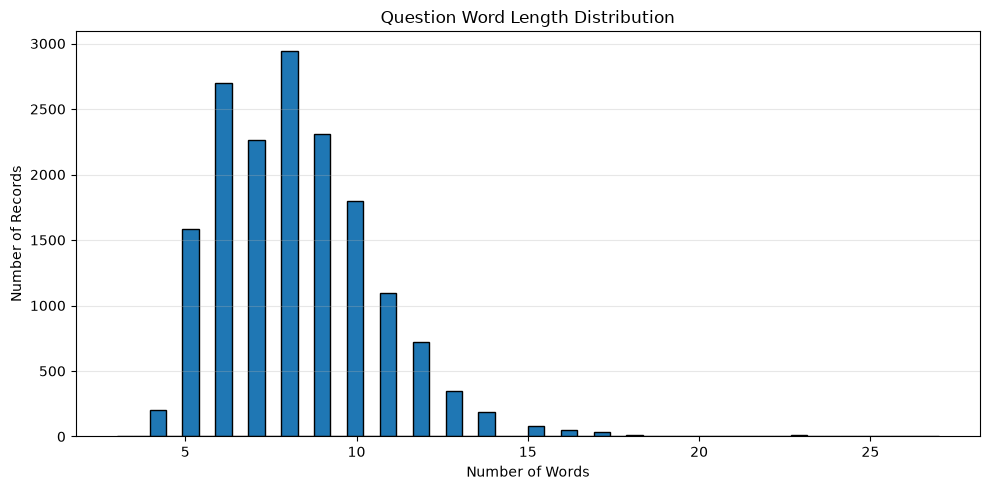

Answer Length


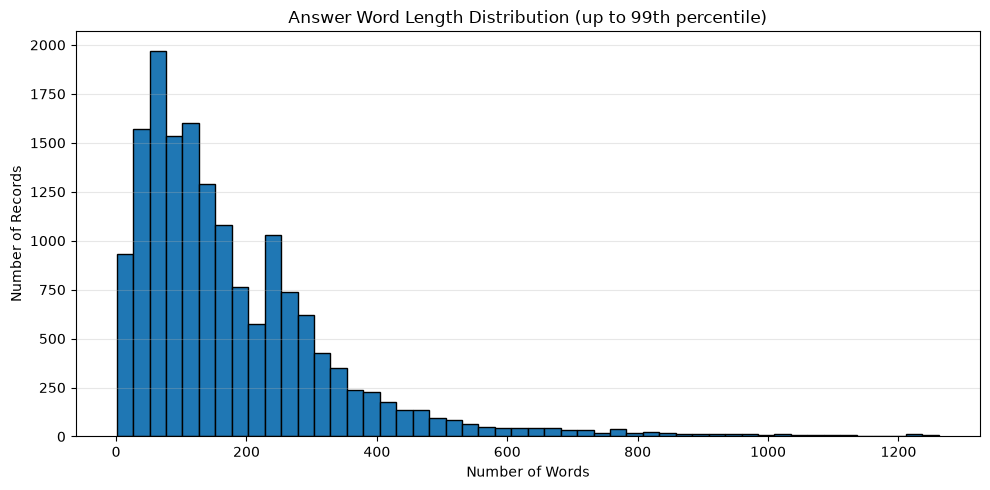

Focus Areas


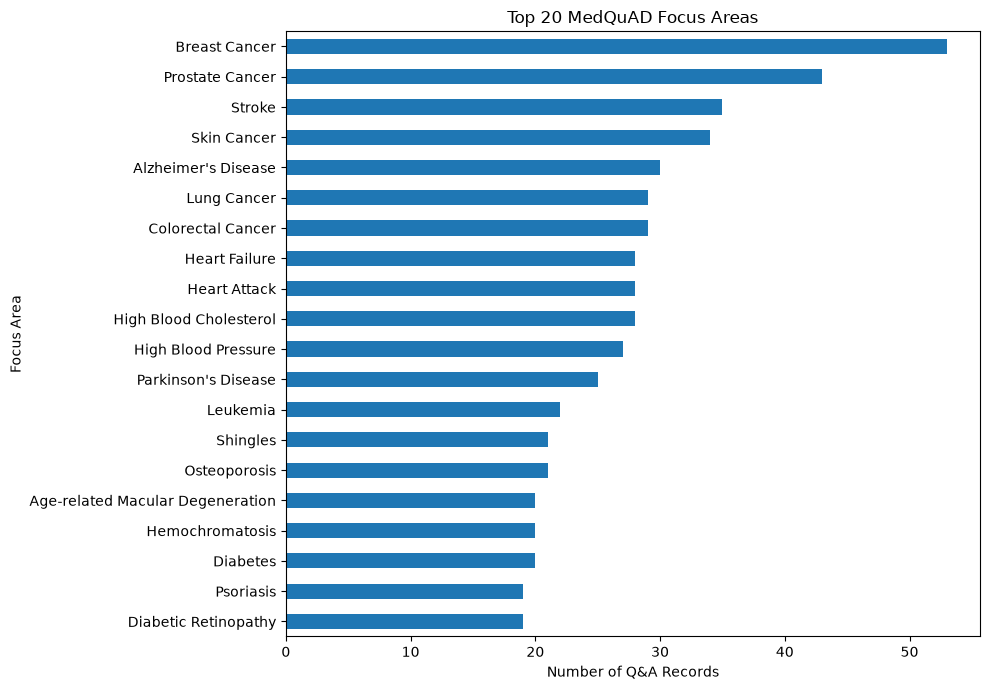

Sources


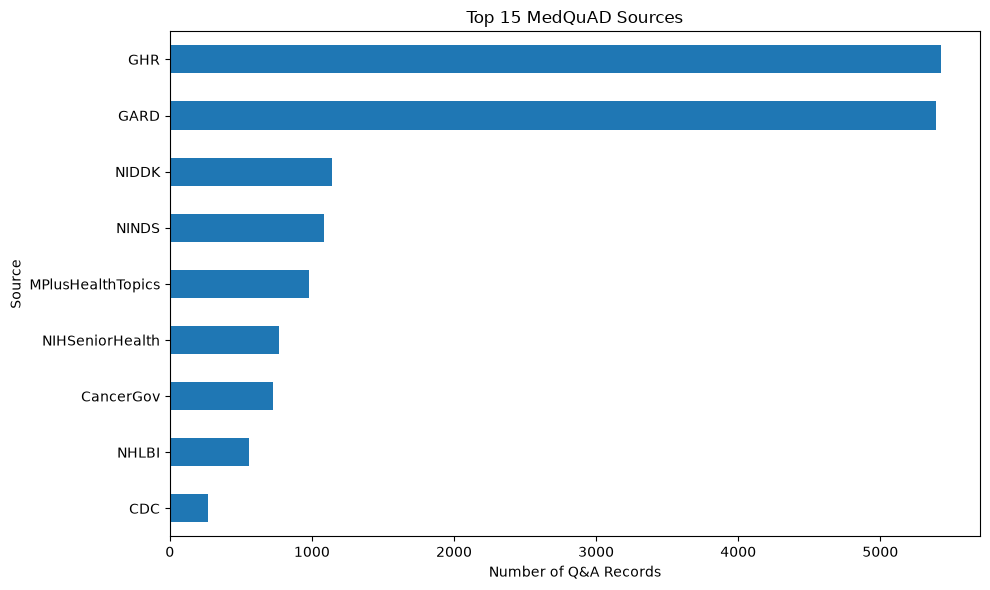

Question vs Answer Length


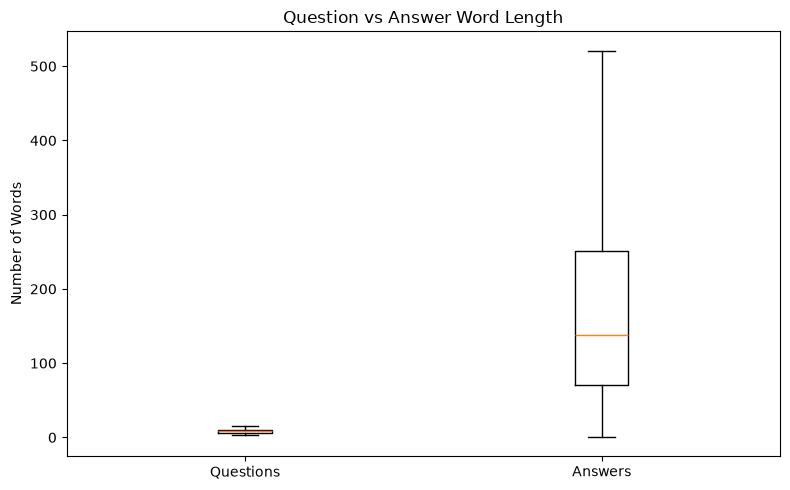

In [20]:
# Generate EDA Visualizations

import matplotlib.pyplot as plt

figures = {
    "Question Length": eda.plot_text_length_distribution(
        medquad_cleaned_df, "question"
    ),
    "Answer Length": eda.plot_text_length_distribution(
        medquad_cleaned_df, "answer", percentile=0.99
    ),
    "Focus Areas": eda.plot_focus_area_distribution(
        medquad_cleaned_df, top_n=20
    ),
    "Sources": eda.plot_source_distribution(
        medquad_cleaned_df
    ),
    "Question vs Answer Length": eda.plot_question_answer_length(
        medquad_cleaned_df
    ),
}

for name, fig in figures.items():
    print(name)
    display(fig)
    plt.close(fig)

## Exploratory Data Analysis (EDA) — MedQuAD Dataset

### 1. Dataset Overview

The MedQuAD dataset was preprocessed to ensure data quality before implementing the MedGemma + Retrieval-Augmented Generation (RAG) pipeline.

| Metric | Result |
|---|---:|
| Original records | 16,412 |
| Cleaned records | 16,359 |
| Records removed | 53 |
| Duplicate rows removed | 48 |
| Records with missing answers removed | 5 |
| Missing focus-area values filled | 14 |
| Remaining missing values | 0 |
| Total features | 4 |

The cleaned dataset contains four columns: `question`, `answer`, `source`, and `focus_area`.

**Key finding:** The dataset is suitable for further feature engineering and retrieval preparation. However, additional checks for repeated questions, conflicting answers, and evaluation leakage are necessary.

### 2. Question Length Distribution

The question-length histogram shows that most medical questions are relatively short, with the highest concentration around 5–12 words.

**Observations:**
- Questions follow a positively skewed distribution.
- Most questions use straightforward medical language.
- Relatively few questions are unusually long.
- The short-question structure is suitable for semantic embedding and similarity-based retrieval.

**Implication for RAG:** Question embeddings can be used to retrieve relevant MedQuAD records. However, short questions may lack context, so retrieval should also consider the medical focus area.

### 3. Answer Length Distribution

The answer-length histogram shows substantial variation in medical response lengths, with a right-skewed distribution.

The EDA identified **164 long-answer records**, with the 99th-percentile threshold at approximately **1,263 words**.

Only **9 answers** contain five words or fewer.

**Observations:**
- Medical answers are considerably longer than their corresponding questions.
- Some answers contain extensive descriptions of symptoms, treatments, or medical conditions.
- Very long answers could introduce irrelevant information into a retrieved context.
- Long answers may exceed the desired context budget when multiple documents are retrieved.

**Implication for RAG:** We should introduce answer chunking rather than embedding and retrieving every long answer as a single document. An initial experiment could use chunks of approximately 300–500 tokens, with overlap where needed. The optimal size must be determined through retrieval evaluation.

### 4. Medical Focus Area Distribution

The dataset contains multiple medical focus areas, but their representation is uneven.

Frequently represented conditions include:

- Breast Cancer
- Prostate Cancer
- Stroke
- Skin Cancer
- Alzheimer's Disease
- Lung Cancer
- Colorectal Cancer
- Heart Failure
- Heart Attack
- High Blood Pressure

**Key finding:** The dataset has substantial coverage of cancer, neurological conditions, and cardiovascular diseases.

**Research concern:** Unequal topic representation may produce different retrieval performance across medical conditions. Conditions with fewer records may be harder to retrieve accurately.

**Implication for RAG:** Evaluate retrieval quality across multiple medical focus areas rather than relying only on overall accuracy.

### 5. Data Source Distribution

The dataset contains records from nine source categories.

| Source | Records | Percentage |
|---|---:|---:|
| GHR | 5,430 | 33.19% |
| GARD | 5,389 | 32.94% |
| NIDDK | 1,144 | 6.99% |
| NINDS | 1,088 | 6.65% |
| MPlusHealthTopics | 981 | 6.00% |
| NIHSeniorHealth | 769 | 4.70% |
| CancerGov | 729 | 4.46% |
| NHLBI | 559 | 3.42% |
| CDC | 270 | 1.65% |

**Key finding:** GHR and GARD together contribute approximately **66.13%** of the dataset.

**Research concern:** The source distribution is imbalanced, potentially influencing which medical information is retrieved most frequently.

**Implication for RAG:** Preserve source metadata in the FAISS document store and evaluate retrieval results across different sources. The chatbot should display the source of retrieved information where possible.

### 6. Duplicate Questions and Multiple Answers

The EDA identified:

- **2,255 records** containing repeated questions.
- **875 distinct questions** that appear more than once.
- Several questions associated with multiple unique answers.

For example:

| Medical question | Unique answers |
|---|---:|
| What is (are) High Blood Cholesterol? | 19 |
| What is (are) Medicare and Continuing Care? | 14 |
| What is (are) Skin Cancer? | 13 |
| What is (are) Stroke? | 13 |
| What is (are) Breast Cancer? | 12 |

**Key finding:** Repeated questions are not necessarily erroneous. Some contain different, potentially complementary medical explanations.

**Research concern:** Random train-validation-test splitting could place the same question, or closely related questions, into multiple subsets, causing evaluation leakage.

**Implication for RAG:** Group repeated questions during dataset splitting, investigate answer differences, and exclude held-out evaluation records from the retrieval index.

### 7. Question vs. Answer Length Comparison

The box plot demonstrates a substantial difference between question and answer lengths.

**Observations:**
- Questions have relatively small length variation.
- Answers have much greater length variation.
- Answer lengths show a wide spread even after extreme outliers are excluded from the visualization.

**Implication for MedGemma:** The model should generate concise, evidence-grounded responses rather than reproducing lengthy retrieved passages. Response length and medical factuality should both be evaluated.

### 8. Recommendations for MedGemma + RAG

Based on the EDA, the following steps are recommended:

1. **Semantic retrieval:** Generate embeddings for MedQuAD questions and relevant answer chunks using a sentence embedding model.
2. **Document chunking:** Split lengthy medical answers into smaller passages while preserving their source and focus-area metadata.
3. **Duplicate handling:** Group repeated questions and inspect potentially conflicting answers before creating evaluation splits.
4. **Metadata preservation:** Retain `source`, `focus_area`, and document identifiers in the retrieval index.
5. **Leakage prevention:** Keep held-out evaluation questions and their answers outside the RAG knowledge base.
6. **Medical factuality evaluation:** Measure retrieval relevance, evidence support, unsupported claims, and performance across different medical topics.

### 9. Conclusion

The MedQuAD EDA demonstrates that the cleaned dataset provides a useful foundation for developing a MedGemma-based medical question-answering system with RAG.

However, three important challenges remain:

- **Long and variable medical answers**, requiring careful chunking and context selection.
- **Repeated questions with multiple answers**, requiring duplicate-aware evaluation and evidence handling.
- **Imbalanced medical topic and source coverage**, requiring evaluation across different medical domains.

These findings justify implementing a retrieval pipeline that combines semantic search, metadata preservation, evidence-grounded generation, and medical safety evaluation.

The next development phase will focus on **data preparation for RAG, embedding generation, and FAISS vector indexing**.
)

sampling_report

**The fact that the mean (314) is much higher than the median (213.5) confirms the long right tail we saw in EDA.**

In [38]:
# Threshold Analysis
thresholds = [
    128,
    256,
    512,
    768,
    1024,
    2048
]

for threshold in thresholds:

    count = (
        medquad_features_df["target_token_length"]
        > threshold
    ).sum()

    percentage = (
        count / len(medquad_features_df)
    ) * 100

    print(
        f"Above {threshold:4} tokens: "
        f"{count:3} / {len(medquad_features_df)} "
        f"({percentage:.2f}%)"
    )

Above  128 tokens: 345 / 500 (69.00%)
Above  256 tokens: 219 / 500 (43.80%)
Above  512 tokens:  71 / 500 (14.20%)
Above  768 tokens:  33 / 500 (6.60%)
Above 1024 tokens:  17 / 500 (3.40%)
Above 2048 tokens:   4 / 500 (0.80%)


In [39]:
# Truncation Analysis
from features.feature_engineering import truncation_analysis

truncation_report = truncation_analysis(
    medquad_features_df
)

truncation_report

{'total_records': 500,
 'max_input_length': 64,
 'inputs_exceeding_limit': 0,
 'inputs_fitting_limit': 500,
 'input_truncation_percentage': 0.0,
 'input_coverage_percentage': 100.0,
 'max_target_length': 512,
 'targets_exceeding_limit': 71,
 'targets_fitting_limit': 429,
 'target_truncation_percentage': 14.2,
 'target_coverage_percentage': 85.8}

# Data Splitting

In [ ]:
from features.data_splitting import split_data

(
    train_df,
    validation_df,
    test_df,
    split_report
) = split_data(
    medquad_features_df
)

In [41]:
split_report

{'total_records': 500,
 'train_records': 400,
 'validation_records': 50,
 'test_records': 50,
 'train_percentage': 80.0,
 'validation_percentage': 10.0,
 'test_percentage': 10.0,
 'train_unique_questions': 398,
 'validation_unique_questions': 50,
 'test_unique_questions': 50,
 'train_validation_question_overlap': 0,
 'train_test_question_overlap': 0,
 'validation_test_question_overlap': 0,
 'random_state': 42}

In [44]:
# Save the split datasets to CSV files
from features.data_splitting import save_splits

save_report = save_splits(
    train_df,
    validation_df,
    test_df
)

save_report

{'output_directory': 'data\\processed',
 'train_path': 'data\\processed\\train.csv',
 'validation_path': 'data\\processed\\validation.csv',
 'test_path': 'data\\processed\\test.csv',
 'train_records': 400,
 'validation_records': 50,
 'test_records': 50,
 'total_records_saved': 500}

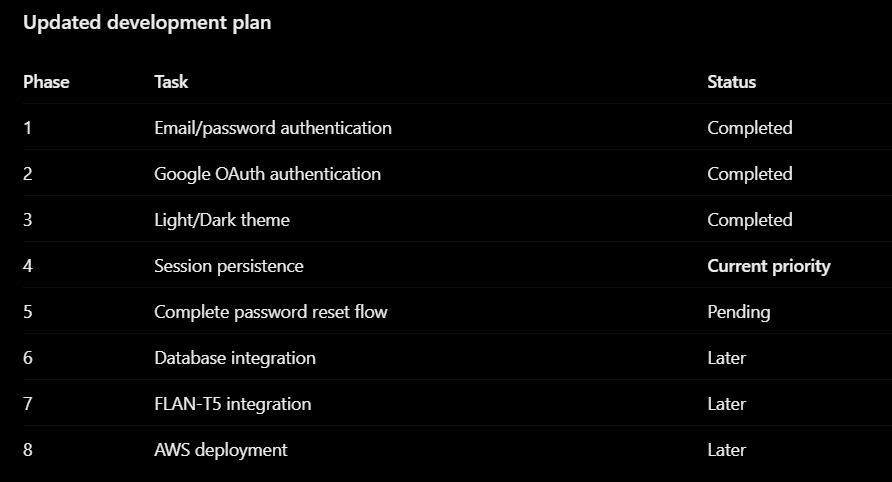